# When should a hot start change the scouting report?

Joseph Smarrelli · September 2026

A player starts the season shooting 43% from three. The staff still needs a working forecast for the next game. Carrying forward 43% treats every early make as if it has settled the question; ignoring the start discards potentially useful information.

This project reconstructs January 1, 2026 forecasts and evaluates the attempts that came afterward. An empirical Bayes update performed better than both the early percentage and a forecast based only on earlier history. The gain over earlier history was small. Most of the improvement came from avoiding an overreaction to the early percentage.

Across **46,184 later attempts from 312 players**, log loss was **0.65417 for the updated forecast**, **0.65436 for the history-only forecast**, and **0.65818 for the early-season percentage**. These are historical backtests built in September 2026, not forecasts claimed to have been published in January.



In [1]:
from pathlib import Path
import os, sys
root = Path.cwd()
if root.name == 'notebooks':
    root = root.parent
sys.path.insert(0, str(root))
os.chdir(root)
import pandas as pd
from IPython.display import display, Image
from src import shooter_updates
summary = shooter_updates.run()
summary

{'prior_alpha': np.float64(127.87932603376352),
 'prior_beta': np.float64(224.7312038700297),
 'history_discount': 1.0,
 'forecast_date': '2026-01-01',
 'minimum_early_attempts': 30,
 'forecast_players': 315,
 'evaluated_players': 312,
 'players_without_later_attempts': 3,
 'evaluation_attempts': 46184,
 'predictive_90_coverage': np.float64(0.9326923076923077),
 'updated_vs_raw_loss': {'difference': -0.004015252792827622,
  'lower': -0.004807197967097755,
  'upper': -0.0031831757769044434},
 'updated_vs_prior_loss': {'difference': -0.00019041681226216435,
  'lower': -0.00034195403770581297,
  'upper': -3.952597495253054e-05}}

## Results
The following table is regenerated from the pinned inputs.

In [2]:
pd.read_csv('results/shooter_validation.csv')

,model,log_loss,brier,attempts
0,Previous-season league rate,0.654786,0.231066,46184
1,Early-season percentage,0.658185,0.232514,46184
2,Previous-history forecast,0.654360,0.230870,46184
3,Updated Bayesian forecast,0.654170,0.230782,46184


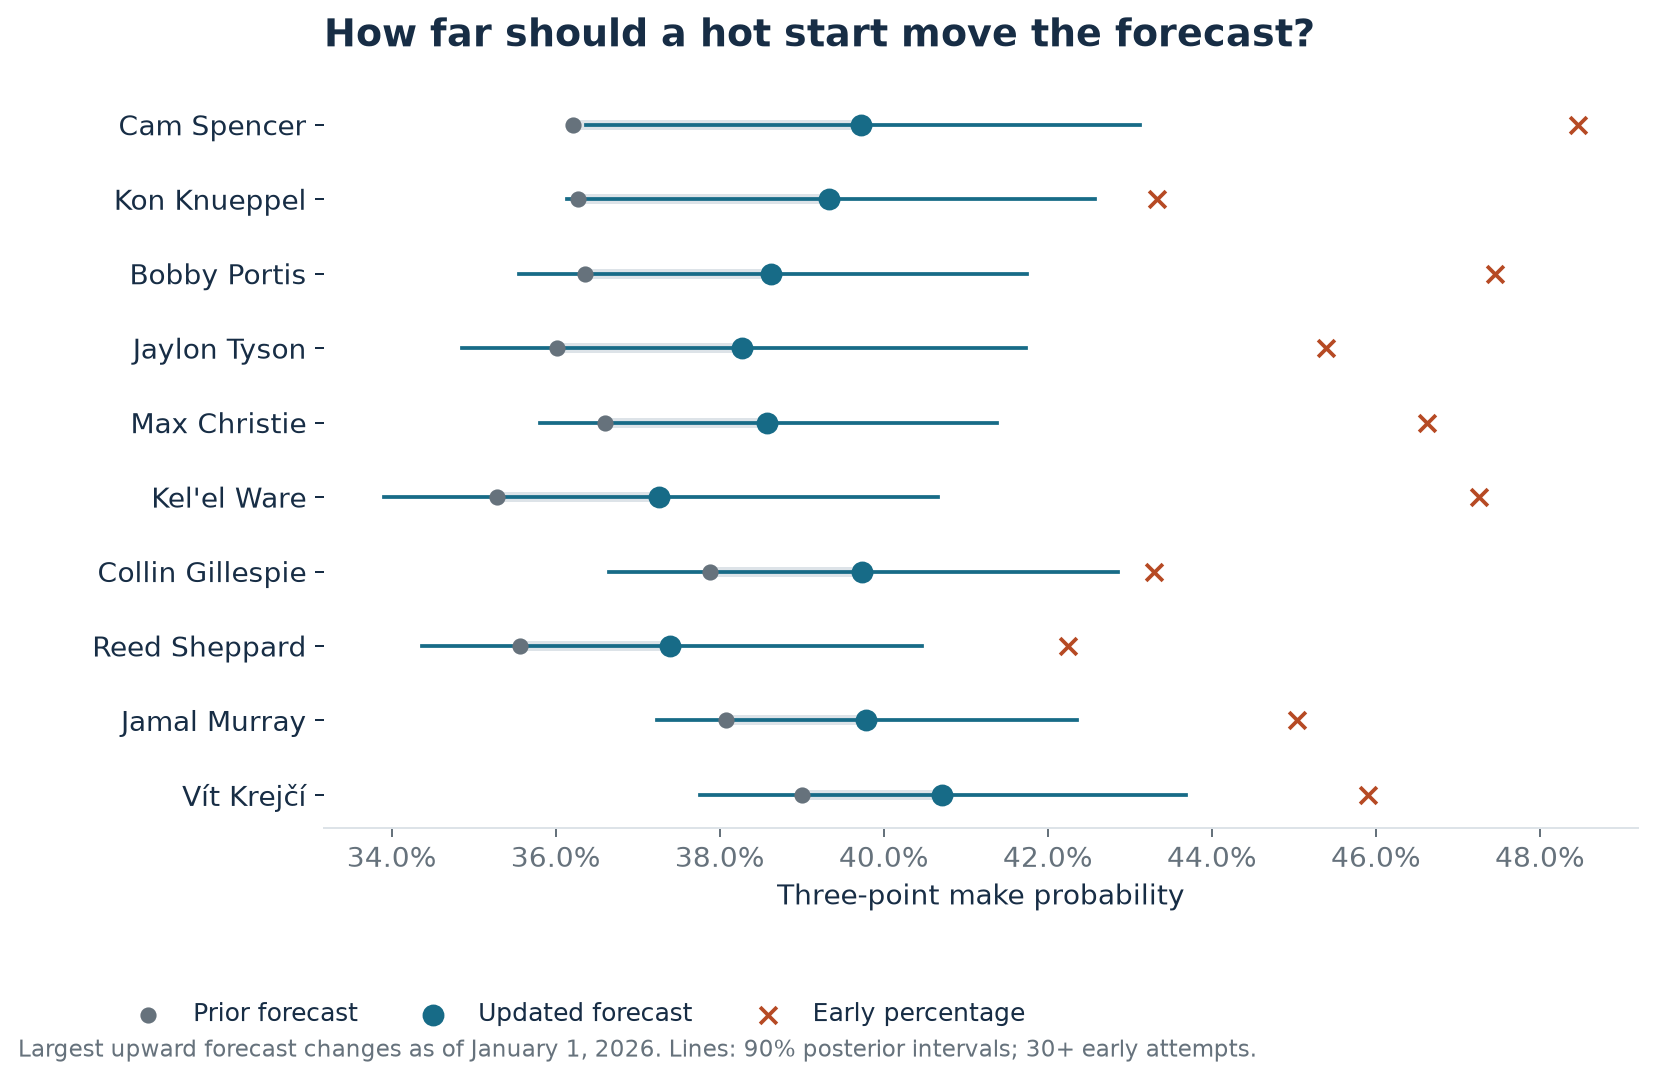

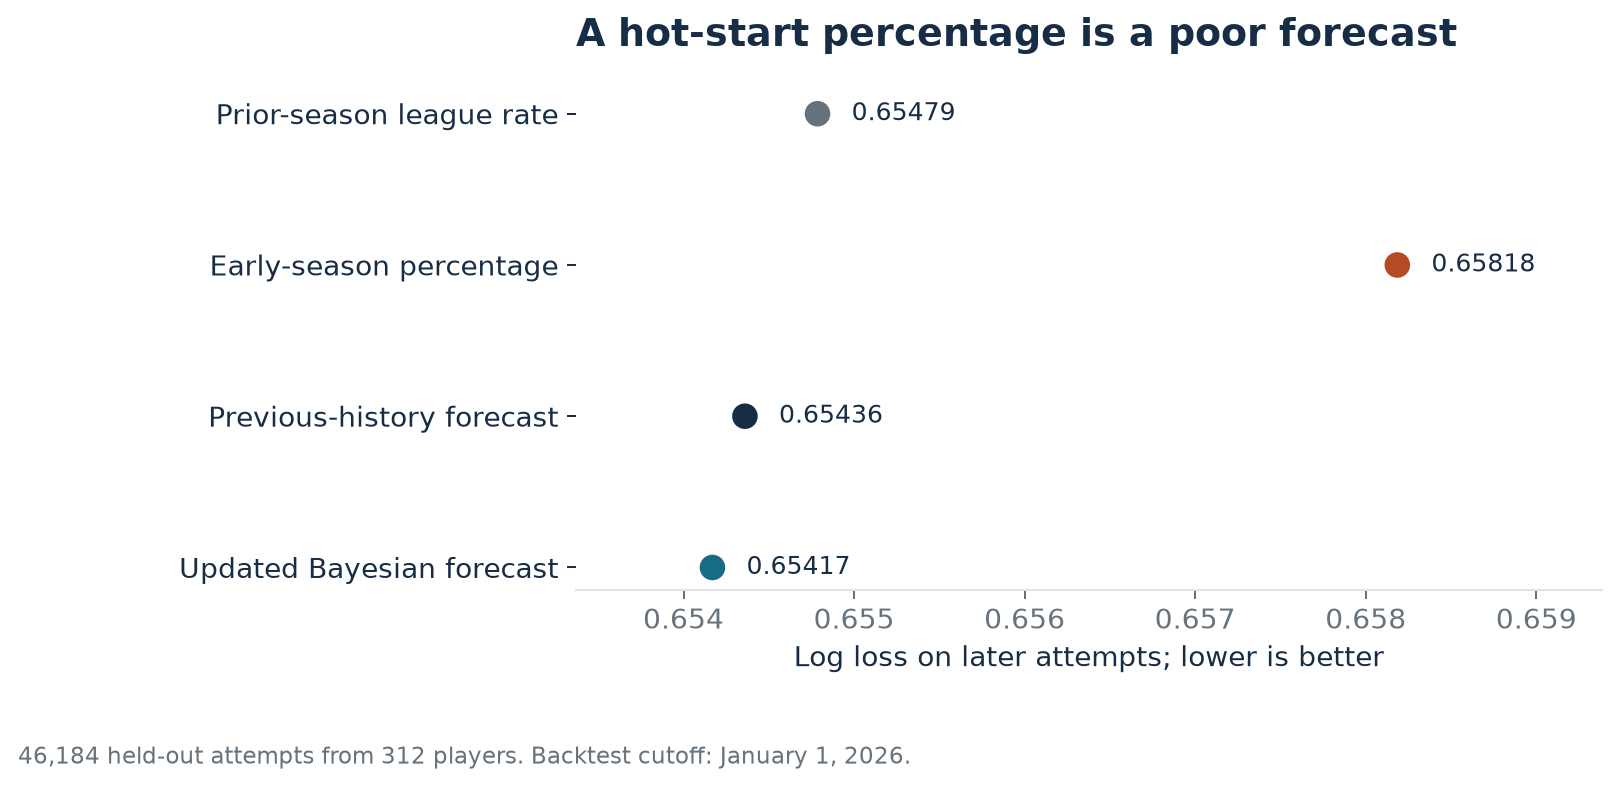

In [3]:
display(Image(filename='figures/shooter_updates.png'))
display(Image(filename='figures/shooter_validation.png'))

## Recalculate an individual forecast
Compare the posterior formula with the exported value.

In [4]:
players = pd.read_csv('results/shooter_forecasts.csv')
r = players.loc[players.player.eq('Collin Gillespie')].iloc[0]
recalculated = r.alpha / (r.alpha + r.beta)
assert abs(recalculated - r.posterior_mean) < 1e-12
r[['player', 'early_attempts', 'early_rate', 'prior_forecast', 'posterior_mean', 'low90', 'high90', 'later_attempts', 'later_rate']]

player            Collin Gillespie
early_attempts                 231
early_rate                  0.4329
prior_forecast            0.378746
posterior_mean            0.397372
low90                     0.366507
high90                    0.428585
later_attempts               347.0
later_rate                0.380403
Name: 214, dtype: object

In [5]:
pd.read_csv('results/shooter_tuning.csv')

,history_discount,validation_logloss,attempts
0,1.00,0.656792,47682
1,0.50,0.656880,47682
2,0.25,0.657005,47682
3,0.10,0.657135,47682
4,0.00,0.657260,47682


## Interpretation and limits
Read the complete accompanying article for denominators, uncertainty, model selection, and the basketball decisions this analysis cannot identify. The results here are historical research, not a claim of team deployment.